## Collaborative Multi-Agent in LangGraph - Command Version


The typical workflow here would be to have the following:

- A Researcher Agent which can leverage tools like search to get live information from user queries
- A Chart Generator Agent which is an expert in taking data and building visualizations in Python
- A router which will help in calling the right agent and tools based on the current state in the agent.

<h4>Install Open AI, and LangChain dependencies</h4>

In [1]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate,MessagesPlaceholder
import os
from dotenv import load_dotenv
load_dotenv()

True

<h4>Setup Enviroment Keys</h4>

In [2]:
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")
TAVILY_API_KEY  = os.getenv("TAVILY_API_KEY")

## Build Collaborative Multi-Agent System

Here we will build the key components of our collaborative multi-agent system

## Create Tools

Here we will be using the [Tavily API](https://tavily.com/#api) for our web searches


PythonREPL as a tool that allows an agent to execute Python code, rather than a normal Python execution/import mechanism.

In [4]:
from typing import Annotated
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_core.tools import tool
from langchain_experimental.utilities import PythonREPL



tv_search = TavilySearchResults(max_results = 5, search_depth = "advanced", max_tokens = 100000)
repl = PythonREPL()

@tool
def python_repl(code:Annotated[str,"The Python code to execute to generate your chat."]):
    """Use this to exceute python code.
    if you want to see the output of a value
    you should print it out with `print(. . .)`.
    This is visible to the user. 
    """
    try:
        result = repl.run(code)
        
    except BaseException as e:
        return f"Failed to execute Error: {repr(e)}"
    result_str = f"Successfully exceuted:\n```python\n{code}\n```\nStdout: {result}"
    return {result_str + "\n\nIf you have completed all tasks, respond with FINAL ANSWER"}


### Graph State

We first define the state of the graph. This will just a list of messages, along with a key to track the most recent sender

In [5]:
import operator
from typing import Annotated,Sequence, TypedDict
from langchain_core.messages import BaseMessage
# This defines the object that is passed between each node
# in the graph. We will create different nodes for each agent and tool
class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], operator.add]
    sender:str

### Create Agents

We will create two main agents here:

1. The Researcher Agent which can access the web search tool to make web searches to get information on user queries
2. The Chart Agent which can use python to create data visualizations

In [ ]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
# Initialize the LLM with the correct model and temperature
llm = ChatOpenAI(model="gpt-4o", temperature=0)
search_tool = [tv_search]
search_tool_name = tv_search.name
research_prompt  = ChatPromptTemplate.from_messages(
    [
        ("system",f""" You are a helpful AI assistant, collaborating with other assistants.
                          Use the provided tools to progress towards answering the question.
                          If you are unable to fully answer, that's OK,
                          another assistant with different tools will help where you left off.
                          Execute what you can to make progress.
                          If you or any of the other assistants have the final answer or deliverable,
                          prefix your response with FINAL ANSWER so the team knows to stop.

                          You have access to the following tools:
                          {search_tool_name}

                          You should provide accurate data for use
                         and source code shouldn't be the final answer
         
         """
         ),
        MessagesPlaceholder(variable_name="messages")
    ]
)

research_agent = (research_prompt 
                    |
                  llm.bind_tools(search_tool)
                )

In [16]:
chart_tool = [python_repl]
chart_tool_name = python_repl.name
chart_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",f"""You are a helpful AI assistant, collaborating with other assistants.
                          Use the provided tools to progress towards answering the question.
                          If you are unable to fully answer, that's OK,
                          another assistant with different tools will help where you left off.
                          Execute what you can to make progress.
                          If you or any of the other assistants have the final answer or deliverable,
                          prefix your response with FINAL ANSWER so the team knows to stop.

                          You have access to the following tools:
                          {chart_tool_name}

                          Run the python code to display the chart
                       """
        ),
        MessagesPlaceholder(variable_name="messages")
    ]
)
chart_agent  = (chart_prompt | llm.bind_tools(chart_tool))

### Define Agent Nodes

Instead of using a separate router with `add_conditional_edges()`, each node will return a
LangGraph `Command`.

`Command` lets a node do two things at the same time:

1. Update the shared graph state.
2. Dynamically decide which node should execute next.

In [17]:
from langgraph.types import Command
from langchain_core.messages import AIMessage

def research_agent_node(state):
    result = research_agent.invoke(state)
    
    # The Researcher requested a tool.
    if result.tool_calls:
        return Command(
            update={
                "messages": [result],
                "sender": "researcher_agent",
            },
            goto="call_tool",
        )
    
    # The Researcher decided that the work is completed
    if "FINAL ANSWER" in result.content:
        return Command(
            update={
                "messages": [result],
                "sender": "researcher_agent",
            },
            goto= "__end__",
        )
    
    #Otherwise, hand the work to Chart agent
    return Command(
        update={
            "messages": [result],
            "sender":"researcher_agent",
        },
        goto="chart_generator_agent",
    )

In [18]:
def chart_agent_node(state):
    result  = chart_agent.invoke(state)
    
    # The chart agent requested a tool.
    if result.tool_calls:
        return Command(
            update= {
                "messages": [result],
                "sender":"chart_generator_agent",
            },
            goto="call_tool",
        )
    
    # The Chart agent decided that work is completed
    if "FINAL ANSWER" in result.content:
        return Command(
            update={
                "messages": [result],
                "sender": "chart_generator_agent",
            },
            goto="__end__",
        )
    
    # Otherwise hand the work back to Researcher agent
    
    return Command(
        update={
            "messages": [result],
            "sender":"chart_generator_agent",
        },
        goto="researcher_agent"
    )
    

### Define Tool Node

The `ToolNode` executes the tool requested by the current agent.

After the tool finishes, our wrapper uses `Command` to send execution back to
the agent that originally requested the tool.


In [19]:
from langgraph.prebuilt import ToolNode
tools = [tv_search,python_repl]
tool_node = ToolNode(tools)

def call_tool_node(state):
    #Execute whichever tool the current agent requested.
    result  = tool_node.invoke(state) ## tool call and tool param in state
     # sender tells us which agent requested the tool.
    # Command sends execution back to that same agent.
    return Command(
        update={
            "messages": result['messages'],
        },
        goto=state['sender'],
    )

### Dynamic Agent Navigation with Command

There is no separate router in this version.

Each agent decides what should happen next by returning a `Command`:

- If the agent requests a tool → go to `call_tool`
- If the agent has finished → go to `END`
- Otherwise → hand off to the other specialized agent

This demonstrates dynamic navigation using LangGraph's `Command` construct.


No separate router function is required in this version.

The routing decision is made directly by each node through `Command(goto=...)`.

### Define the Multi-Agent Graph

The graph contains two specialized agents and one tool node.

Unlike the original version, we do not define `add_conditional_edges()`.
The `Command` returned by each node controls the next step dynamically.


In [20]:
from langgraph.graph import END, StateGraph
agent  = StateGraph(AgentState)
agent.add_node("researcher_agent",research_agent_node)
agent.add_node("chart_generator_agent", chart_agent_node)
agent.add_node("call_tool",call_tool_node)

# No add_conditional_edges() is required.
# Each node returns Command(goto=...) to dynamically choose the next node.
agent.set_entry_point("researcher_agent")
agent = agent.compile()


### How Command Changes the Flow

The important part of this example is that the routing decision is now made inside the nodes.

For example:

```python
return Command(
    update={"sender": "Researcher"},
    goto="chart_generator"
)
```

This means:

> Update the shared state and send execution to the Chart Generator.

When an agent needs a tool:

```python
return Command(
    update={"sender": "Researcher"},
    goto="call_tool"
)
```

The tool node then uses the `sender` value to return control to the agent that requested the tool.

Conceptually:

```text
User
  ↓
Researcher Agent
  │
  ├── Command → call_tool
  │                 ↓
  │            Tool executes
  │                 ↓
  │            Command → Researcher
  │
  └── Command → Chart Generator
                       │
                       ├── Command → call_tool
                       │                 ↓
                       │            Tool executes
                       │                 ↓
                       │            Command → Chart Generator
                       │
                       └── Command → END
```


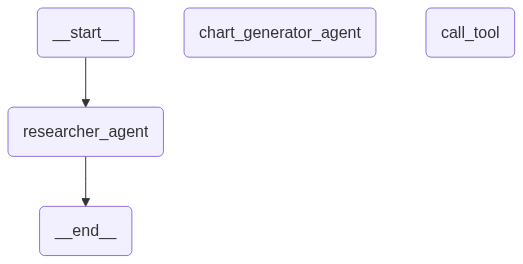

In [13]:
from IPython.display import Image, display, Markdown
display(Image(agent.get_graph().draw_mermaid_png()))

In [ ]:
# prompt = """Fetch the data of the top 10 countries with the highest GDP in the world.
#             Then use this data and draw a bar chart.
#          """

# response = agent.invoke({"messages": [('human', prompt)]},
#                         # Maximum number of steps to take in the graph
#                         {"recursion_limit": 150},)

Task researcher_agent with path ('__pregel_pull', 'researcher_agent') wrote to unknown channel branch:to:chart_generator, ignoring it.



🔵 NODE: researcher_agent
----------------------------------------------------------------------
🤖 AI DECISION
🔨 TOOL: tavily_search_results_json
🧹 ARGUMENTS: {'query': 'top 10 countries by GDP 2023'}

🔵 NODE: call_tool
----------------------------------------------------------------------
🔨 TOOL RESULT (tavily_search_results_json):
[{"title": "GDP by Country (2026) - IMF", "url": "https://www.worldometers.info/gdp/gdp-by-country", "content": "| 163 | Maldives | $8.13 billion | $8,130,000,000 | 3.02% | $19,464 |\n| 164 | Cayman Islands | $7.77 billion (WB, 2024) | $7,765,336,505 | 3.76% | $104,293 |\n| 165 | Isle of Man | $7.58 billion (WB, 2023) | $7,576,129,933 | −2.04% | $90,015 |\n| 166 | Yemen | $7.43 billion | $7,435,000,000 | 0.51% | $384 |\n| 167 | Fiji | $6.35 billion | $6,352,000,000 | 2.43% | $6,802 |\n| 168 | French Polynesia | $6.32 billion (WB, 2024) | $6,323,716,355 | 1.13% | $22,440 |\n| 169 | South Sudan | $6.07 billion | $6,069,000,000 | 4.14% | $488 |\n| 170 | Surina

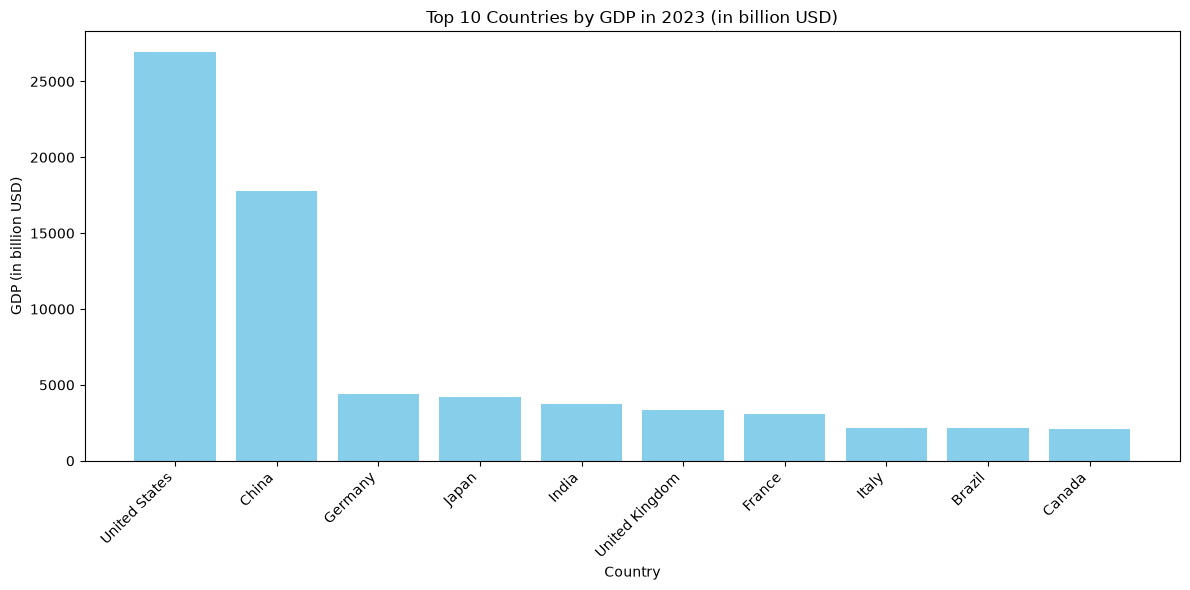


🔵 NODE: call_tool
----------------------------------------------------------------------
🔨 TOOL RESULT (python_repl):
{'Successfully exceuted:\n```python\nimport matplotlib.pyplot as plt\n\n# Data for the top 10 countries by GDP\ncountries = ["United States", "China", "Germany", "Japan", "India", \n             "United Kingdom", "France", "Italy", "Brazil", "Canada"]\ngdp_values = [26954, 17786, 4430, 4231, 3730, 3332, 3052, 2190, 2132, 2122]\n\n# Create a bar chart\nplt.figure(figsize=(12, 6))\nplt.bar(countries, gdp_values, color=\'skyblue\')\nplt.title(\'Top 10 Countries by GDP in 2023 (in billion USD)\')\nplt.xlabel(\'Country\')\nplt.ylabel(\'GDP (in billion USD)\')\nplt.xticks(rotation=45, ha=\'right\')\nplt.tight_layout()\n\n# Show the plot\nplt.show()\n```\nStdout: \n\nIf you have completed all tasks, respond with FINAL ANSWER'}

🔵 NODE: chart_generator_agent
----------------------------------------------------------------------
🤖 AI:
FINAL ANSWER: The bar chart displaying the 

In [22]:
from langchain_core.messages import HumanMessage

prompt = """
Fetch the data of the top 10 countries with the highest GDP in the world.

Then use this data and draw a bar chart.
"""

for event in agent.stream(
    {
        "messages": [
            HumanMessage(content=prompt)
        ]
    },
    config={
        "recursion_limit": 150
    },
):
    print("\n" + "=" * 70)

    # event is typically:
    # {"NodeName": {"messages": [...]}}

    for node_name, node_output in event.items():

        print(f"🔵 NODE: {node_name}")
        print("-" * 70)

        if not node_output:
            continue

        # Get messages generated by this node
        messages = node_output.get("messages", [])

        for message in messages:

            # Human message
            if message.type == "human":
                print(f"🤷‍♂️ USER:\n{message.content}")

            # AI message
            elif message.type == "ai":

                # AI decided to call a tool
                if message.tool_calls:
                    print("🤖 AI DECISION")

                    for tool_call in message.tool_calls:
                        print(f"🔨 TOOL: {tool_call['name']}")
                        print(f"🧹 ARGUMENTS: {tool_call['args']}")

                # Normal AI response
                elif message.content:
                    print(f"🤖 AI:\n{message.content}")

            # Tool result
            elif message.type == "tool":
                print(f"🔨 TOOL RESULT ({message.name}):")
                print(message.content)


print("\n" + "=" * 70)
print("✅ GRAPH EXECUTION COMPLETED")